In [1]:
import pandas as pd

In [5]:
df = pd.read_csv("/content/spam.csv", encoding='latin-1')

In [6]:
df

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN
...,...,...,...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...,NaN,NaN,NaN
5568,ham,Will Ì_ b going to esplanade fr home?,NaN,NaN,NaN
5569,ham,"Pity, * was in mood for that. So...any other s...",NaN,NaN,NaN
5570,ham,The guy did some bitching but I acted like i'd...,NaN,NaN,NaN


In [7]:
from sklearn.model_selection import train_test_split

# Keep only the necessary columns and rename them
cleaned_df = df[['v1', 'v2']].rename(columns={'v1': 'label', 'v2': 'text'})

# Split the dataset into train (80%) and test (20%) sets
train_df, test_df = train_test_split(cleaned_df, test_size=0.2, random_state=42, stratify=cleaned_df['label'])

print(f"Training set shape: {train_df.shape}")
print(f"Testing set shape: {test_df.shape}")

# Display the first few rows of the training set
display(train_df.head())

Training set shape: (4457, 2)
Testing set shape: (1115, 2)


,label,text
184,ham,Going on nothing great.bye
2171,ham,I wont. So wat's wit the guys
5422,ham,Ok k..sry i knw 2 siva..tats y i askd..
4113,ham,Where are you ? What do you do ? How can you s...
4588,ham,Have you not finished work yet or something?


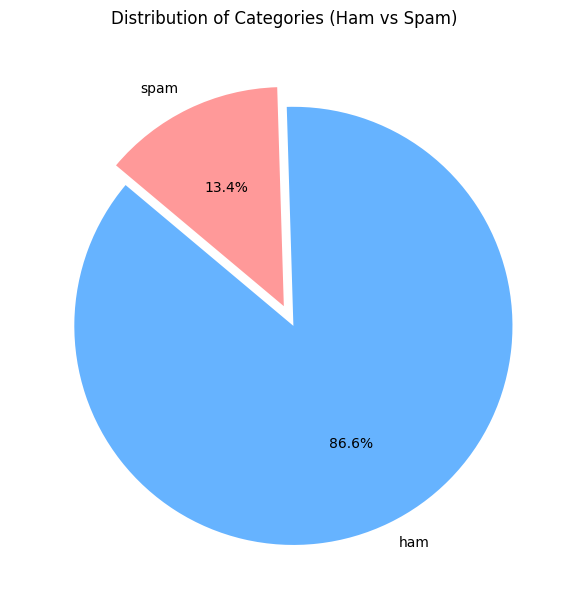

In [8]:
import matplotlib.pyplot as plt

# Count the occurrences of each category
category_counts = cleaned_df['label'].value_counts()

# Plot a pie chart
plt.figure(figsize=(6, 6))
plt.pie(
    category_counts,
    labels=category_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=['#66b3ff', '#ff9999'],
    explode=(0.1, 0)  # Explode the spam category to highlight it
)
plt.title('Distribution of Categories (Ham vs Spam)')
plt.tight_layout()
plt.show()

In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, accuracy_score

# Define a model pipeline
model_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(stop_words='english', lowercase=True)),
    ('classifier', MultinomialNB())
])

# Train the model
model_pipeline.fit(train_df['text'], train_df['label'])

# Evaluate the model on our test set
y_pred = model_pipeline.predict(test_df['text'])
print(f"Accuracy on Test Set: {accuracy_score(test_df['label'], y_pred):.2%}\n")
print(classification_report(test_df['label'], y_pred))

Accuracy on Test Set: 96.86%

              precision    recall  f1-score   support

         ham       0.97      1.00      0.98       966
        spam       1.00      0.77      0.87       149

    accuracy                           0.97      1115
   macro avg       0.98      0.88      0.92      1115
weighted avg       0.97      0.97      0.97      1115



In [11]:
def predict_message(message):
    """Predicts whether a given message is spam or ham."""
    prediction = model_pipeline.predict([message])[0]
    probabilities = model_pipeline.predict_proba([message])[0]
    classes = model_pipeline.classes_

    print(f"Message: \"{message}\"")
    print(f"Prediction: {prediction.upper()}")
    print(f"Confidence: {classes[0]}: {probabilities[0]:.2%}, {classes[1]}: {probabilities[1]:.2%}\n")

# Demo predictions with new custom data
predict_message("Hey, are we still meeting for lunch today at 1 PM?")
predict_message("URGENT! You have won a 1-week all-expenses-paid trip to Hawaii! Call 09061701461 now to claim your prize!")

Message: "Hey, are we still meeting for lunch today at 1 PM?"
Prediction: HAM
Confidence: ham: 99.51%, spam: 0.49%

Message: "URGENT! You have won a 1-week all-expenses-paid trip to Hawaii! Call 09061701461 now to claim your prize!"
Prediction: SPAM
Confidence: ham: 19.55%, spam: 80.45%



In [14]:
#@title ✉️ Test Your Own Message

message_text = "Subject: Appointment Confirmation: Dr. Smith on Tuesday, Oct 14 Body: Hi [Name], This is a friendly reminder of your upcoming appointment with Dr. Smith on Tuesday, October 14, 2026, at 10:00 AM. Please arrive 15 minutes early and bring your ID and insurance card. If you need to reschedule, call our office at 555-0199. Best regards, City Health Clinic" #@param {type:"string"}

if message_text.strip() == "":
    print("Please type a message in the text field above and run the cell.")
else:
    predict_message(message_text)

Message: "Subject: Appointment Confirmation: Dr. Smith on Tuesday, Oct 14 Body: Hi [Name], This is a friendly reminder of your upcoming appointment with Dr. Smith on Tuesday, October 14, 2026, at 10:00 AM. Please arrive 15 minutes early and bring your ID and insurance card. If you need to reschedule, call our office at 555-0199. Best regards, City Health Clinic"
Prediction: HAM
Confidence: ham: 90.28%, spam: 9.72%

